<a href="https://colab.research.google.com/github/Edgar121207/MIS140-Introduction-to-Machine-Learning/blob/main/MIS140_A3_Al_Farizi_200000079.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###**MIS 140 Assessment 3**

Dataset Import

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/drive/MyDrive/NovoBank.csv')

df.head()

,customer_id,sex,age,marital_status,number_of_dependents,annual_income,account_type,credit_limit,number_of_accounts,months_since_opening,outstanding_balance,utilisation_ratio,total_amount_of_transactions,total_number_of_transactions,number_of_contacts_over_12_months,months_inactive_over_12_months,status
0,1.431131e+09,M,50.0,Married,1,$110K and Over,Silver,7522.0,3,40,1057,0.141,2533,62,2,3,Active
1,1.427610e+09,M,41.0,Single,3,$70K - $90K,Silver,9246.0,4,33,0,0.000,4611,91,3,1,Active
2,1.425868e+09,F,49.0,Single,4,Less than $50K,Silver,2636.0,1,36,1257,0.477,7136,82,3,1,Active
3,1.559760e+09,F,53.0,Unknown,2,Less than $50K,Silver,2081.0,2,37,1342,0.645,4428,80,2,3,Active
4,1.436426e+09,M,39.0,Married,3,$110K and Over,Silver,3281.0,6,36,1682,0.513,4109,69,2,3,Active


##**PART 1: Data Preprocessing**

In [ ]:
# 1. Missing Data Check
print("--- Missing Values ---")
print(df.isnull().sum())

# 2. Data Types Check (Inconsistency)
print("\n--- Data Types ---")
print(df.info())

# 3. Outlier Check (Summary Statistics)
# We focus on numerical columns to see if there are extreme min/max values
print("\n--- Descriptive Statistics for Outlier Detection ---")
display(df.describe())

# Specific check for strings that might have 'Unknown' instead of NaN
print("\n--- Value Counts for Categorical Columns (Hidden Missing Data) ---")
for col in df.select_dtypes(include=['object']).columns:
    print(f"{col}: {df[col].unique()[:5]}...")

--- Missing Values ---
customer_id                          10
sex                                   0
age                                  10
marital_status                       10
number_of_dependents                  0
annual_income                         0
account_type                         10
credit_limit                          0
number_of_accounts                    0
months_since_opening                  0
outstanding_balance                   0
utilisation_ratio                    10
total_amount_of_transactions          0
total_number_of_transactions          0
number_of_contacts_over_12_months     0
months_inactive_over_12_months        0
status                                0
dtype: int64

--- Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 17 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   customer_id           

,customer_id,age,number_of_dependents,credit_limit,number_of_accounts,months_since_opening,outstanding_balance,utilisation_ratio,total_amount_of_transactions,total_number_of_transactions,number_of_contacts_over_12_months,months_inactive_over_12_months
count,1.011700e+04,10117.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10117.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,1.478335e+09,46.452605,2.346203,8631.953698,3.812580,35.928409,1162.814061,0.274876,4404.086304,113.999506,2.455317,2.341167
std,7.380072e+07,12.943342,1.298908,9088.776650,1.554408,7.986416,814.987335,0.275688,3397.129254,2220.262376,1.106225,1.010622
min,1.416168e+09,-50.000000,0.000000,1438.300000,1.000000,13.000000,0.000000,0.000000,510.000000,-1000.000000,0.000000,0.000000
25%,1.426069e+09,41.000000,1.000000,2555.000000,3.000000,31.000000,359.000000,0.023000,2155.500000,45.000000,2.000000,2.000000
50%,1.435854e+09,46.000000,2.000000,4549.000000,4.000000,36.000000,1276.000000,0.175000,3899.000000,67.000000,2.000000,2.000000
75%,1.546285e+09,52.000000,3.000000,11067.500000,5.000000,40.000000,1784.000000,0.503000,4741.000000,81.000000,3.000000,3.000000
max,1.656690e+09,999.000000,5.000000,34516.000000,6.000000,56.000000,2517.000000,0.999000,18484.000000,99999.000000,6.000000,6.000000



--- Value Counts for Categorical Columns (Hidden Missing Data) ---
sex: ['M' 'F']...
marital_status: ['Married' 'Single' 'Unknown' 'Divorced' nan]...
annual_income: ['$110K and Over' '$70K - $90K' 'Less than $50K' '$50K - $70K'
 '$90K - $110K']...
account_type: ['Silver' 'Gold' 'Diamond' nan 'Titanium']...
status: ['Active' 'Closed']...


Duplicates

In [ ]:
duplicate_count = df.duplicated().sum()
customer_id_duplicates = df.duplicated(subset=['customer_id']).sum() if 'customer_id' in df.columns else 0

print(f"Total exact row duplicates: {duplicate_count}")
print(f"Total customer_id duplicates: {customer_id_duplicates}")

if duplicate_count > 0 or customer_id_duplicates > 0:
    print("\n--- Sample of duplicated entries ---")
    display(df[df.duplicated(subset=['customer_id'], keep=False)].sort_values(by='customer_id').head())
else:
    print("\nNo duplicates found. The dataset is clean.")

Total exact row duplicates: 0
Total customer_id duplicates: 9

--- Sample of duplicated entries ---


,customer_id,sex,age,marital_status,number_of_dependents,annual_income,account_type,credit_limit,number_of_accounts,months_since_opening,outstanding_balance,utilisation_ratio,total_amount_of_transactions,total_number_of_transactions,number_of_contacts_over_12_months,months_inactive_over_12_months,status
623,NaN,M,45.0,Single,3,$90K - $110K,Silver,8383.0,1,39,0,0.000,2600,44,3,3,Closed
2922,NaN,F,29.0,Single,1,Less than $50K,Silver,3318.0,3,23,927,0.279,3011,83,2,1,Active
3282,NaN,F,51.0,Married,4,Unknown,Silver,3853.0,2,41,696,0.181,2443,38,5,3,Closed
3781,NaN,F,48.0,Unknown,3,Less than $50K,Silver,4850.0,1,36,1022,0.211,4187,86,3,1,Active
3931,NaN,F,43.0,Unknown,3,Less than $50K,Silver,1824.0,3,36,0,0.000,4594,86,2,3,Active


##Missing Values

In [ ]:
# 1. Targeted Imputation (Using original column names)
df['age'] = df['age'].fillna(df['age'].median())
df['utilisation_ratio'] = df['utilisation_ratio'].fillna(df['utilisation_ratio'].median())
df['marital_status'] = df['marital_status'].fillna(df['marital_status'].mode()[0])
df['account_type'] = df['account_type'].fillna(df['account_type'].mode()[0])

# 2. Final Drop for remaining identifiers (like customer_id)
df.dropna(subset=['customer_id'], inplace=True)

print(f"Missing values after logic fix: {df.isnull().sum().sum()}")
print(f"Dataframe shape: {df.shape}")

Missing values after logic fix: 0
Dataframe shape: (10117, 17)


##Outliers

In [ ]:
import numpy as np
from scipy import stats

def identify_outliers_summary(df, col_name):
    # IQR Method
    Q1 = df[col_name].quantile(0.25)
    Q3 = df[col_name].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    iqr_outliers = df[(df[col_name] < lower_bound) | (df[col_name] > upper_bound)]

    # Z-score Method
    z_scores = np.abs(stats.zscore(df[col_name]))
    z_outliers = df[z_scores > 3]

    print(f"--- {col_name} ---")
    print(f"IQR Method: Found {len(iqr_outliers)} outliers")
    print(f"Z-score Method: Found {len(z_outliers)} outliers")
    print(f"IQR Bounds: {lower_bound:.2f} to {upper_bound:.2f}\n")

# Summary
identify_outliers_summary(df, 'age')
identify_outliers_summary(df, 'total_number_of_transactions')
identify_outliers_summary(df, 'total_amount_of_transactions')

--- age ---
IQR Method: Found 12 outliers
Z-score Method: Found 10 outliers
IQR Bounds: 24.50 to 68.50

--- total_number_of_transactions ---
IQR Method: Found 11 outliers
Z-score Method: Found 5 outliers
IQR Bounds: -9.00 to 135.00

--- total_amount_of_transactions ---
IQR Method: Found 895 outliers
Z-score Method: Found 389 outliers
IQR Bounds: -1724.00 to 8620.00



Outliers visualization

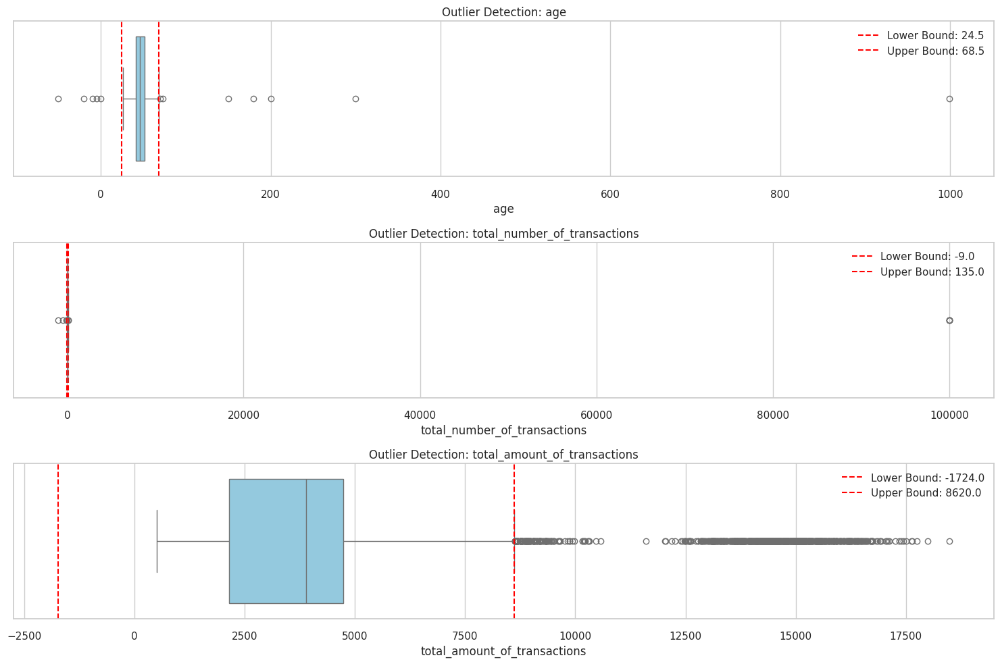

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cols_to_plot = ['age', 'total_number_of_transactions', 'total_amount_of_transactions']
plt.figure(figsize=(15, 10))

for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(3, 1, i)
    sns.boxplot(x=df[col], color='skyblue')

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    plt.axvline(lower, color='red', linestyle='--', label=f'Lower Bound: {lower:.1f}')
    plt.axvline(upper, color='red', linestyle='--', label=f'Upper Bound: {upper:.1f}')
    plt.title(f'Outlier Detection: {col}')
    plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Comprehensive Outlier Treatment
numerical_cols = ['age', 'total_number_of_transactions', 'total_amount_of_transactions', 'credit_limit', 'outstanding_balance']

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = df[col].clip(lower=lower, upper=upper)

# Log transform the capped amount
df['log_total_amount'] = np.log1p(df['total_amount_of_transactions'])
print("Outlier capping applied to all major numerical features.")

Outlier capping applied to all major numerical features.


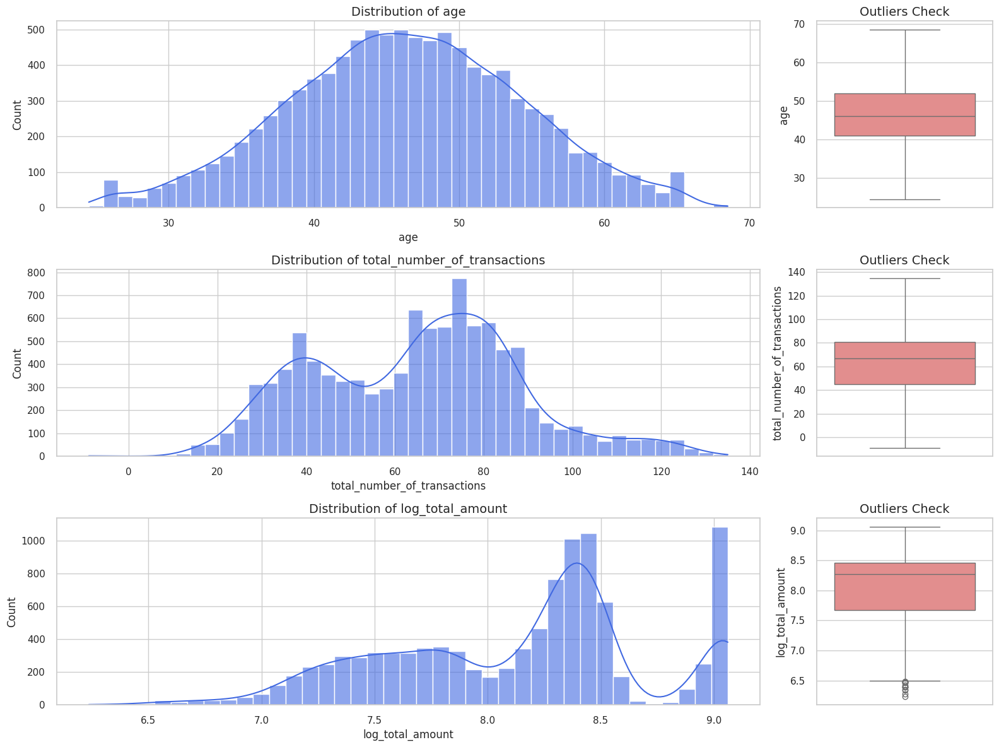

--- Skewness Metrics ---
Original Amount Skew: 0.8367
Log-Transformed Amount Skew: -0.2685


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

cols_to_show = ['age', 'total_number_of_transactions', 'log_total_amount']
fig, axes = plt.subplots(len(cols_to_show), 2, figsize=(16, 12), gridspec_kw={'width_ratios': [0.8, 0.2]})

for i, col in enumerate(cols_to_show):
    # Histogram / KDE
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='royalblue', alpha=0.6)
    axes[i, 0].set_title(f'Distribution of {col}', fontsize=14)

    # Boxplot
    sns.boxplot(y=df[col], ax=axes[i, 1], color='lightcoral')
    axes[i, 1].set_title(f'Outliers Check', fontsize=14)

plt.tight_layout()
plt.show()

print(f"--- Skewness Metrics ---")
print(f"Original Amount Skew: {df['total_amount_of_transactions'].skew():.4f}")
print(f"Log-Transformed Amount Skew: {df['log_total_amount'].skew():.4f}")

### **Refined ML Pipeline: Train-Test Split (Pre-Scaling)**
To prevent data leakage, we split the data *before* any scaling or encoding.

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Define target and basic features
y = df['status'].map({'Active': 0, 'Closed': 1})
X_raw = df.drop(columns=['status'])

# 2. Initial Split (80/20) - Stratified
# Fixed: random_id -> random_state to resolve TypeError
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Raw Training Shape: {X_train_raw.shape}")
print(f"Raw Testing Shape: {X_test_raw.shape}")

Raw Training Shape: (8093, 17)
Raw Testing Shape: (2024, 17)


In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import pandas as pd
import numpy as np

# 1. Feature Engineering & Encoding on Splits
def prepare_features(df_input):
    temp_df = df_input.copy()
    income_map = {'Unknown': 0, 'Less than $50K': 1, '$50K - $70K': 2, '$70K - $90K': 3, '$90K - $110K': 4, '$110K and Over': 5}
    temp_df['annual_income_encoded'] = temp_df['annual_income'].map(income_map)
    account_map = {'Silver': 0, 'Gold': 1, 'Diamond': 2, 'Titanium': 3}
    temp_df['account_type_encoded'] = temp_df['account_type'].map(account_map)

    # One-Hot Encoding (FIXED: drop_first=True to avoid the Dummy Variable Trap/Multicollinearity)
    temp_df = pd.get_dummies(temp_df, columns=['sex', 'marital_status'], prefix=['sex', 'marital'], drop_first=True)

    # FIXED: Dropping 'total_number_of_transactions' to resolve extreme Multicollinearity (VIF > 40)
    cols_to_drop = ['customer_id', 'annual_income', 'account_type', 'total_amount_of_transactions', 'total_number_of_transactions']
    return temp_df.drop(columns=[c for c in cols_to_drop if c in temp_df.columns])

X_train_processed = prepare_features(X_train_raw)
X_test_processed = prepare_features(X_test_raw)

# Ensure both have same dummy columns
X_train_processed, X_test_processed = X_train_processed.align(X_test_processed, join='left', axis=1, fill_value=0)

# 2. Scaling (Fit on Train ONLY)
std_cols = ['age', 'months_since_opening', 'number_of_accounts']
mm_cols = ['credit_limit', 'outstanding_balance', 'utilisation_ratio', 'log_total_amount']

scaler_std = StandardScaler().fit(X_train_processed[std_cols])
scaler_mm = MinMaxScaler().fit(X_train_processed[mm_cols])

X_train_processed[std_cols] = scaler_std.transform(X_train_processed[std_cols])

X_test_processed[std_cols] = scaler_std.transform(X_test_processed[std_cols])

X_train_processed[mm_cols] = scaler_mm.transform(X_train_processed[mm_cols])
X_test_processed[mm_cols] = scaler_mm.transform(X_test_processed[mm_cols])

# Synchronization
X_train_final = X_train_processed
y_train_final = y_train

print("Pipeline hardened: Multicollinearity resolved by dropping redundant dummy categories (drop_first=True).")

Pipeline hardened: Multicollinearity resolved by dropping redundant dummy categories (drop_first=True).


##Feature Encoding and Engineering

In [ ]:
# Refined Encoding (Moved to ensure it captures the scaled numerical values)
income_map = {
    'Unknown': 0,
    'Less than $50K': 1,
    '$50K - $70K': 2,
    '$70K - $90K': 3,
    '$90K - $110K': 4,
    '$110K and Over': 5
}
df['annual_income_encoded'] = df['annual_income'].map(income_map)

account_map = {'Silver': 0, 'Gold': 1, 'Diamond': 2, 'Titanium': 3}
df['account_type_encoded'] = df['account_type'].map(account_map)

# Nominal encoding - creating the final ML-ready dataframe from the scaled 'df'
# We drop the original categorical columns that were encoded to ensure ML-readiness
df_encoded = pd.get_dummies(df, columns=['sex', 'marital_status', 'status'], prefix=['sex', 'marital', 'status'])
df_encoded.drop(columns=['annual_income', 'account_type'], inplace=True)

print("Logical encoding fixed, synchronized with scaled features, and redundant string columns dropped.")
display(df_encoded.head())

Logical encoding fixed, synchronized with scaled features, and redundant string columns dropped.


,customer_id,age,number_of_dependents,credit_limit,number_of_accounts,months_since_opening,outstanding_balance,utilisation_ratio,total_amount_of_transactions,total_number_of_transactions,...,annual_income_encoded,account_type_encoded,sex_F,sex_M,marital_Divorced,marital_Married,marital_Single,marital_Unknown,status_Active,status_Closed
0,1.431131e+09,50.0,1,7522.0,3,40,1057,0.141,2533,62,...,5,0,False,True,False,True,False,False,True,False
1,1.427610e+09,41.0,3,9246.0,4,33,0,0.000,4611,91,...,3,0,False,True,False,False,True,False,True,False
2,1.425868e+09,49.0,4,2636.0,1,36,1257,0.477,7136,82,...,1,0,True,False,False,False,True,False,True,False
3,1.559760e+09,53.0,2,2081.0,2,37,1342,0.645,4428,80,...,1,0,True,False,False,False,False,True,True,False
4,1.436426e+09,39.0,3,3281.0,6,36,1682,0.513,4109,69,...,5,0,False,True,False,True,False,False,True,False


##**PART 2: Exploratory Data Analysis (EDA)**

##Data Overview

In [ ]:
!pip install -q ydata-profiling
from ydata_profiling import ProfileReport

# Generate the profile report
profile = ProfileReport(df, title="NovoBank Data Profiling Report", explorative=True)

# Display the report directly in the notebook
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 20/20 [00:00<00:00, 24.25it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

##Customer Attrition Summary



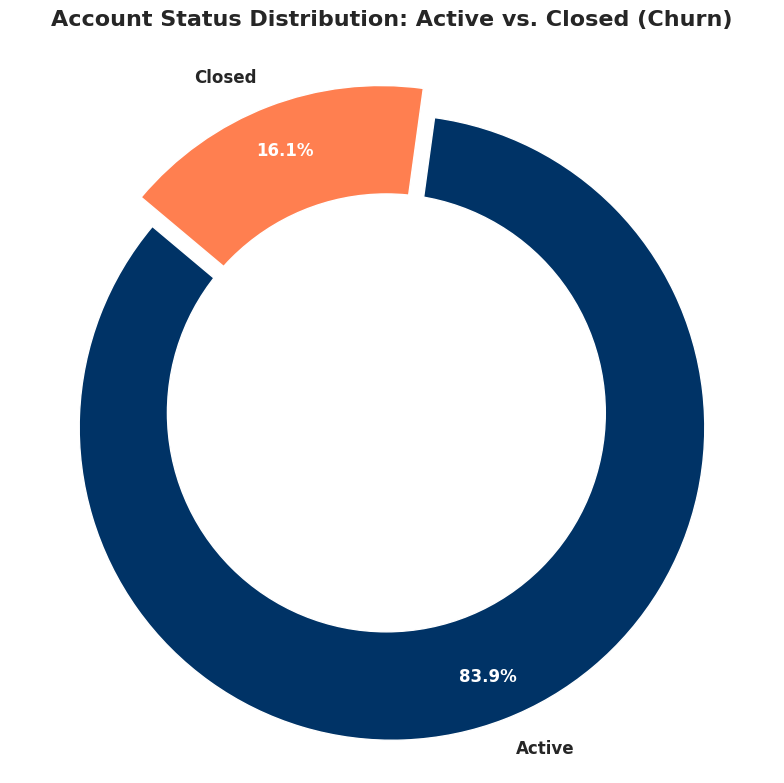

In [ ]:
import matplotlib.pyplot as plt

# Use df_encoded where the dummy variables exist
active_count = df_encoded['status_Active'].sum()
closed_count = df_encoded['status_Closed'].sum()
counts = [active_count, closed_count]
labels = ['Active', 'Closed']
colors = ['#003366', '#FF7F50']

fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    counts,
    labels=labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    pctdistance=0.85,
    explode=(0.05, 0.05),
    textprops={'fontsize': 12, 'weight': 'bold'}
)

centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

for autotext in autotexts:
    autotext.set_color('white')

plt.title('Account Status Distribution: Active vs. Closed (Churn)', fontsize=16, pad=20, weight='bold')
ax.axis('equal')
plt.tight_layout()
plt.show()

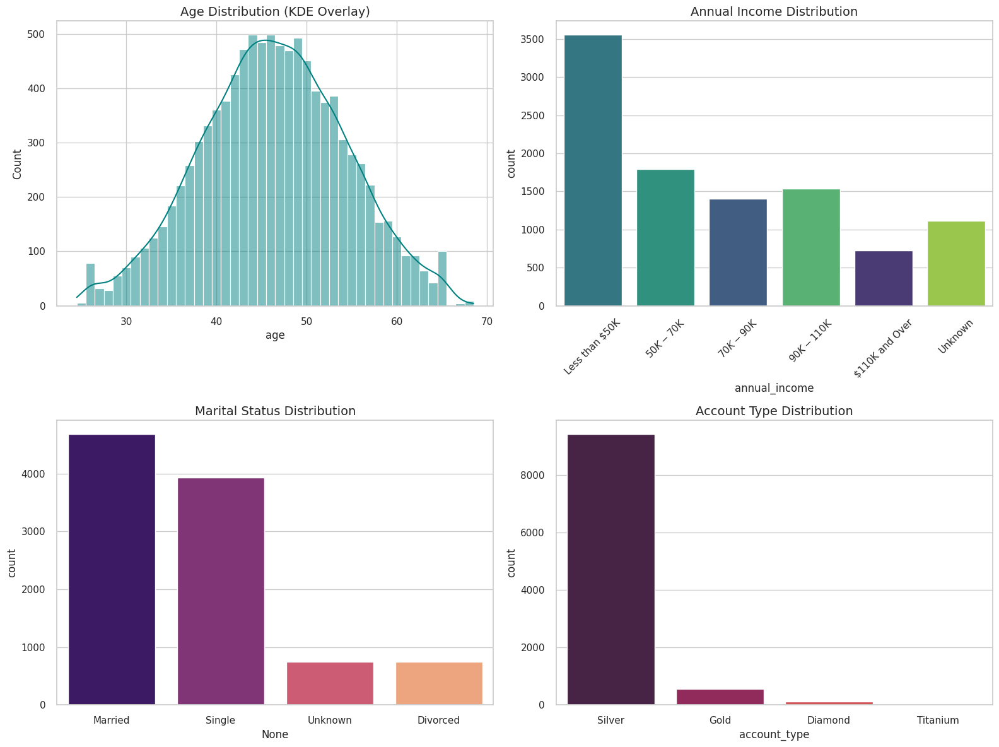

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Age Distribution with KDE
sns.histplot(df['age'], kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Age Distribution (KDE Overlay)', fontsize=14)

# 2. Annual Income Distribution
order_income = ['Less than $50K', '$50K - $70K', '$70K - $90K', '$90K - $110K', '$110K and Over', 'Unknown']
sns.countplot(data=df, x='annual_income', order=order_income, ax=axes[0, 1], palette='viridis', hue='annual_income', legend=False)
axes[0, 1].set_title('Annual Income Distribution', fontsize=14)
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Marital Status Distribution (FIXED: Reconstructing from df_encoded dummy columns)
marital_cols = [col for col in df_encoded.columns if 'marital_' in col]
marital_labels = df_encoded[marital_cols].idxmax(axis=1).str.replace('marital_', '')
sns.countplot(x=marital_labels, ax=axes[1, 0], palette='magma', hue=marital_labels, legend=False)
axes[1, 0].set_title('Marital Status Distribution', fontsize=14)

# 4. Account Type Distribution
sns.countplot(data=df, x='account_type', ax=axes[1, 1], palette='rocket', hue='account_type', legend=False)
axes[1, 1].set_title('Account Type Distribution', fontsize=14)

plt.tight_layout()
plt.show()

##Relationship Anlysis

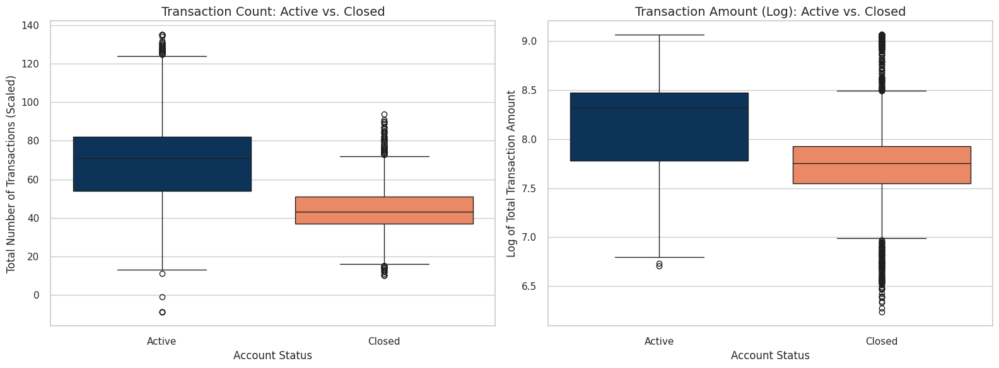

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

status_labels = df_encoded[['status_Active', 'status_Closed']].idxmax(axis=1).str.replace('status_', '')

plt.figure(figsize=(16, 6))

# Total Number of Transactions vs Status
plt.subplot(1, 2, 1)
sns.boxplot(x=status_labels, y=df['total_number_of_transactions'], palette=['#003366', '#FF7F50'], hue=status_labels, legend=False)
plt.title('Transaction Count: Active vs. Closed', fontsize=14)
plt.xlabel('Account Status')
plt.ylabel('Total Number of Transactions (Scaled)')

# Total Amount of Transactions vs Status
plt.subplot(1, 2, 2)
sns.boxplot(x=status_labels, y=df['log_total_amount'], palette=['#003366', '#FF7F50'], hue=status_labels, legend=False)
plt.title('Transaction Amount (Log): Active vs. Closed', fontsize=14)
plt.xlabel('Account Status')
plt.ylabel('Log of Total Transaction Amount')

plt.tight_layout()
plt.show()

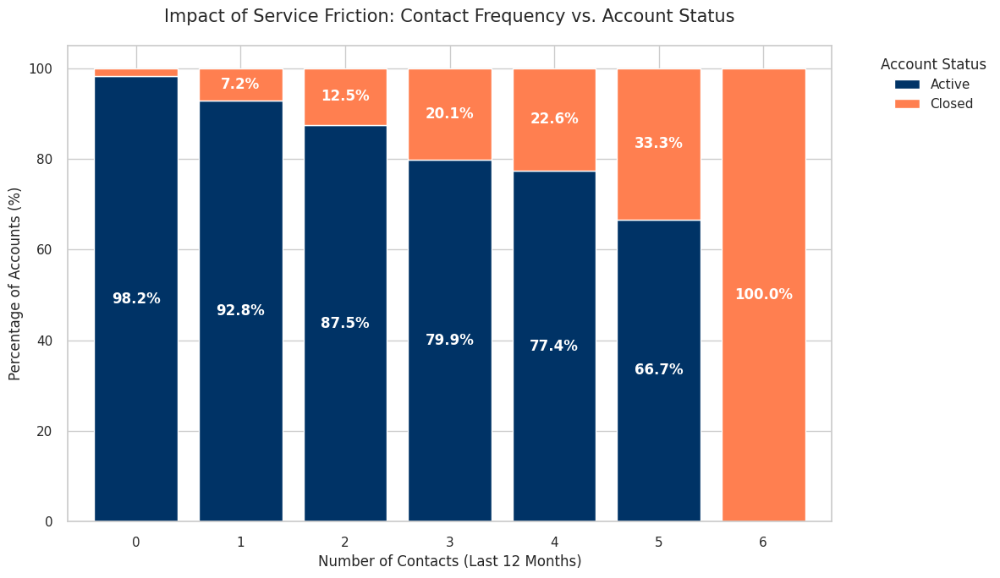

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Prepare data using the reconstructed status_labels
ct = pd.crosstab(df['number_of_contacts_over_12_months'], status_labels)

# Normalize to 100%
ct_pct = ct.div(ct.sum(1), axis=0) * 100

# Visualization
ax = ct_pct.plot(kind='bar', stacked=True, figsize=(12, 7), color=['#003366', '#FF7F50'], width=0.8)

plt.title('Impact of Service Friction: Contact Frequency vs. Account Status', fontsize=15, weight=100, pad=20)
plt.xlabel('Number of Contacts (Last 12 Months)', fontsize=12)
plt.ylabel('Percentage of Accounts (%)', fontsize=12)
plt.legend(title='Account Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)

for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if height > 5:
        ax.text(x + width/2, y + height/2, f'{height:.1f}%',
                horizontalalignment='center', verticalalignment='center',
                color='white', weight='bold')

plt.tight_layout()
plt.show()

##Inter-Feature Analysis

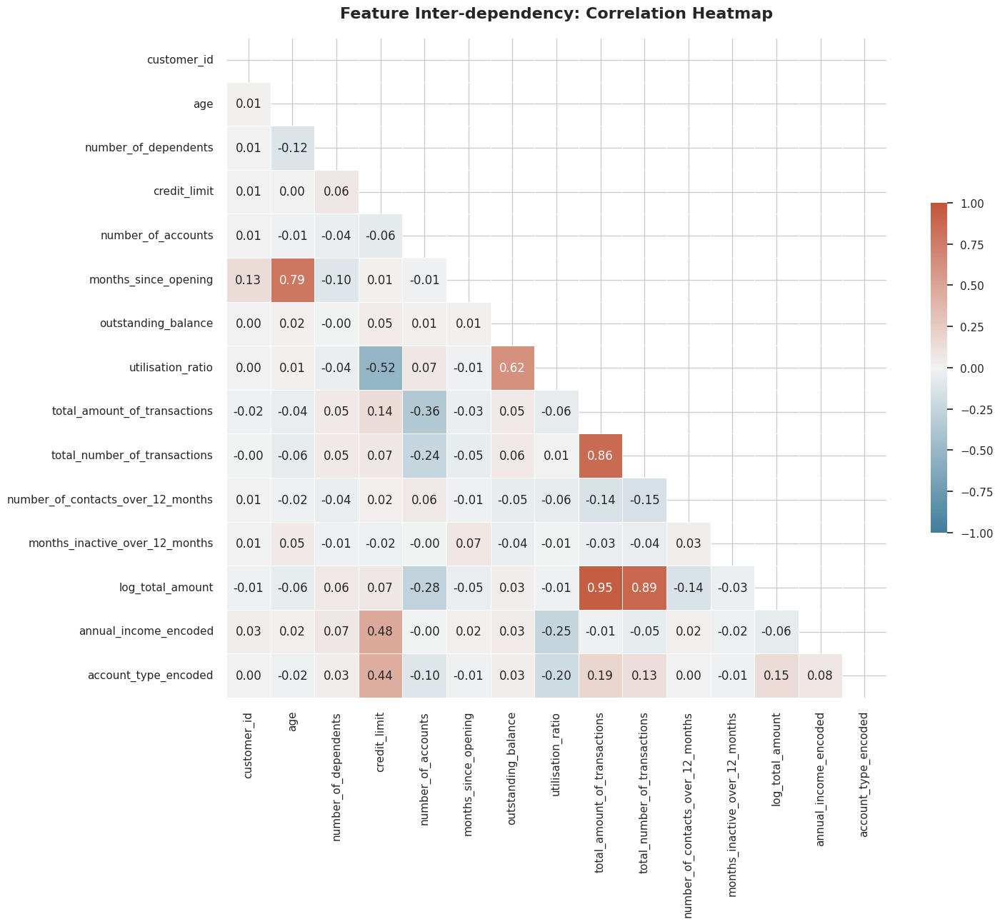

--- Potential Redundancies Identified (> 0.8) ---
('total_amount_of_transactions', 'total_number_of_transactions'): 0.8551
('total_amount_of_transactions', 'log_total_amount'): 0.9499
('total_number_of_transactions', 'total_amount_of_transactions'): 0.8551
('total_number_of_transactions', 'log_total_amount'): 0.8886
('log_total_amount', 'total_amount_of_transactions'): 0.9499
('log_total_amount', 'total_number_of_transactions'): 0.8886


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Calculate Correlation Matrix (using Pearson for linear relationships)
# We exclude non-numeric or low-variance columns if necessary
corr_matrix = df.select_dtypes(include=[np.number]).corr()

# 2. Set up the matplotlib figure
plt.figure(figsize=(16, 12))

# 3. Create a mask to hide the upper triangle (redundant info)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# 4. Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# 5. Draw the heatmap
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=1.0, center=0, vmin=-1.0,
            square=True, linewidths=.5, cbar_kws={'shrink': .5}, annot=True, fmt='.2f')

plt.title('Feature Inter-dependency: Correlation Heatmap', fontsize=16, weight='bold', pad=20)
plt.show()

# 6. Identify high correlations (> 0.8)
high_corr = corr_matrix[(corr_matrix.abs() > 0.8) & (corr_matrix != 1.0)].stack().dropna().to_dict()
if high_corr:
    print('--- Potential Redundancies Identified (> 0.8) ---')
    for pair, val in high_corr.items():
        print(f'{pair}: {val:.4f}')
else:
    print('No extreme redundancies (> 0.8) detected.')

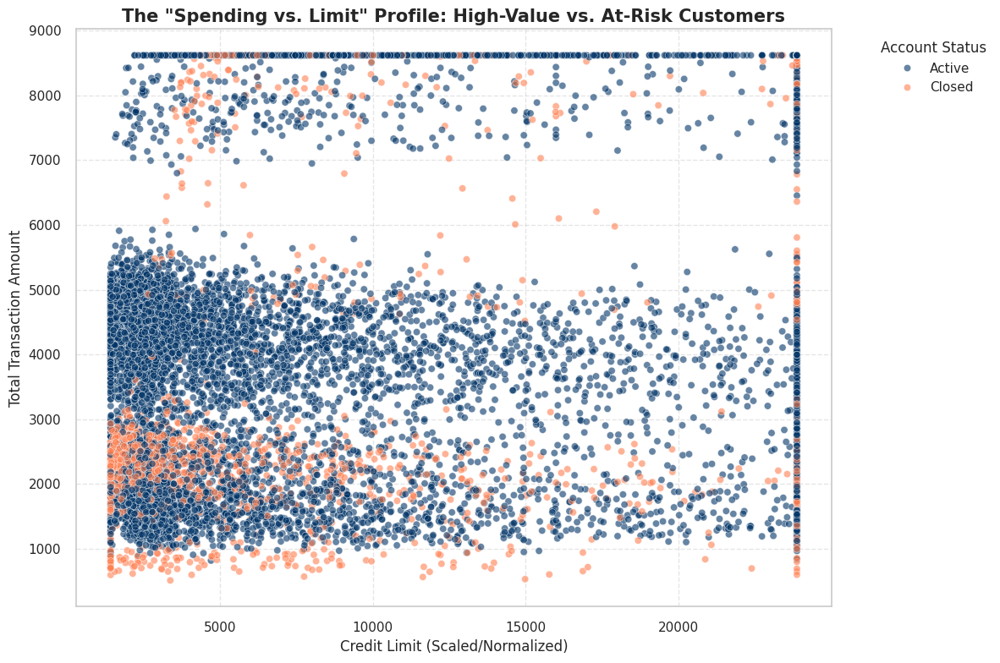

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reconstruct status for the legend
plot_df = df.copy()
plot_df['Account_Status'] = status_labels

plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=plot_df,
    x='credit_limit',
    y='total_amount_of_transactions',
    hue='Account_Status',
    palette={'Active': '#003366', 'Closed': '#FF7F50'},
    alpha=0.6
)

plt.title('The "Spending vs. Limit" Profile: High-Value vs. At-Risk Customers', fontsize=15, weight='bold')
plt.xlabel('Credit Limit (Scaled/Normalized)', fontsize=12)
plt.ylabel('Total Transaction Amount', fontsize=12)
# Move legend outside the plot area
plt.legend(title='Account Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

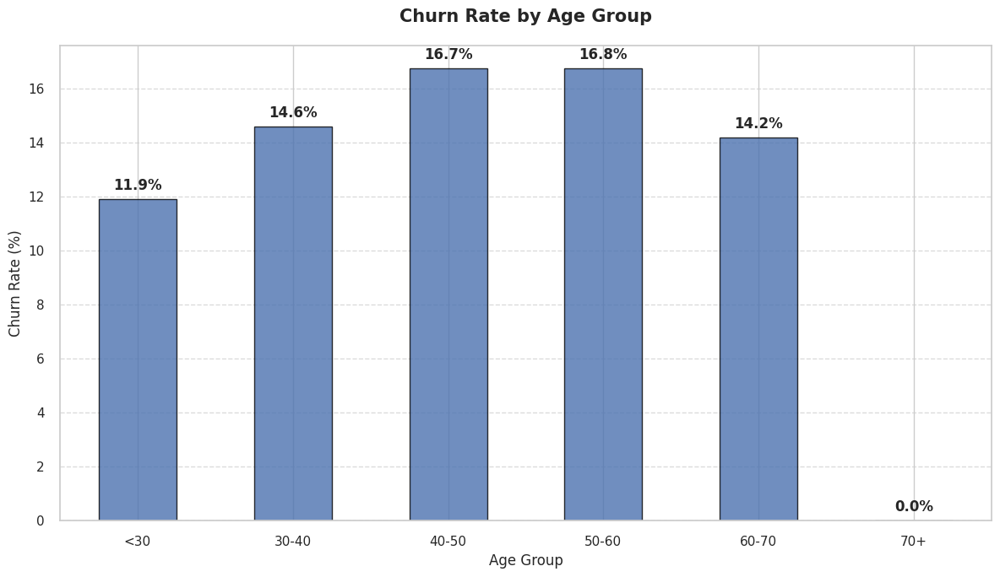

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Use raw age directly
age_original = df['age'].copy()

# 2. Clean invalid age values
age_original = age_original.where((age_original >= 18) & (age_original <= 100), np.nan)

# 3. Create churn indicator safely
# Use original status column if available
if 'status' in df.columns:
    is_churned = df['status'].map({'Active': 0, 'Closed': 1})
else:
    # fallback if you only have df_encoded
    is_churned = df_encoded['status_Closed']

# 4. Create Age Bins
bins = [0, 30, 40, 50, 60, 70, 100]
labels = ['<30', '30-40', '40-50', '50-60', '60-70', '70+']

age_binned = pd.cut(
    age_original,
    bins=bins,
    labels=labels,
    include_lowest=True
)

# 5. Combine into one dataframe
churn_data = pd.DataFrame({
    'Age_Group': age_binned,
    'Is_Churned': is_churned
})

# 6. Remove missing/invalid rows
churn_data = churn_data.dropna(subset=['Age_Group', 'Is_Churned'])

# 7. Calculate churn rate per age group
churn_rate_by_age = (
    churn_data
    .groupby('Age_Group', observed=False)['Is_Churned']
    .mean()
    .reindex(labels)
    * 100
)

# 8. Visualization
plt.figure(figsize=(12, 7))

ax = churn_rate_by_age.plot(
    kind='bar',
    edgecolor='black',
    alpha=0.8
)

plt.title('Churn Rate by Age Group', fontsize=15, weight='bold', pad=20)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Churn Rate (%)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height):
        ax.annotate(
            f'{height:.1f}%',
            (p.get_x() + p.get_width() / 2, height),
            ha='center',
            va='bottom',
            xytext=(0, 5),
            textcoords='offset points',
            weight='bold'
        )

plt.tight_layout()
plt.show()

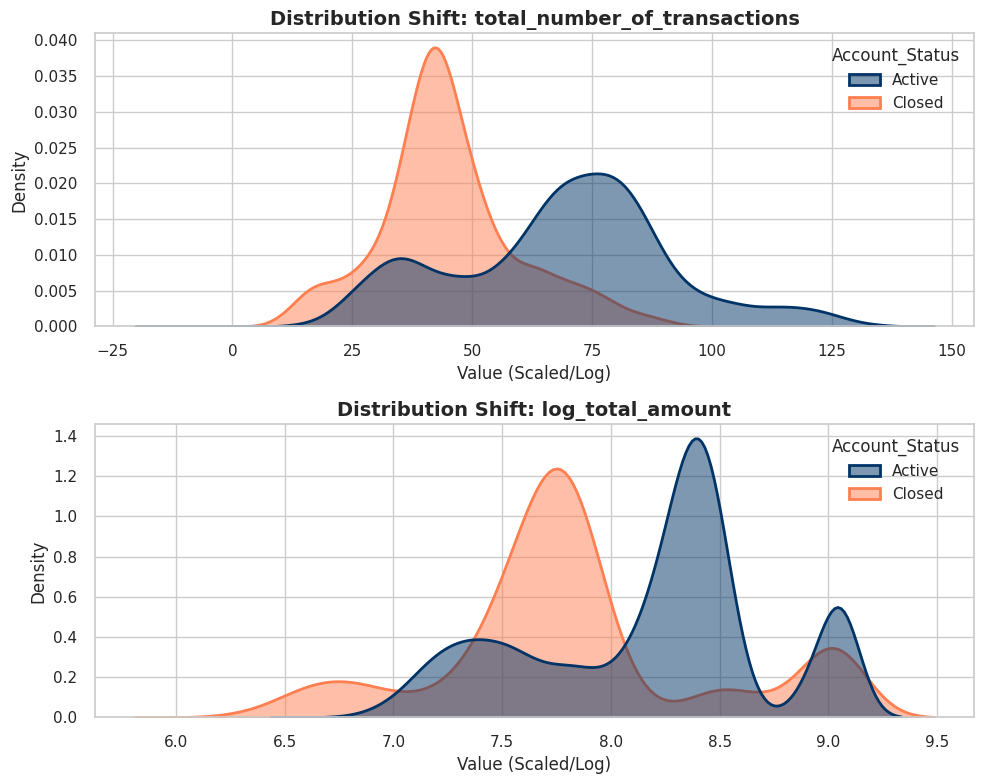

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare data
plot_df = df.copy()
plot_df['Account_Status'] = status_labels

# Set up the figure
features = ['total_number_of_transactions', 'log_total_amount']
fig, axes = plt.subplots(len(features), 1, figsize=(10, 8), sharex=False)

for i, feature in enumerate(features):
    sns.kdeplot(
        data=plot_df,
        x=feature,
        hue='Account_Status',
        fill=True,
        common_norm=False,
        palette={'Active': '#003366', 'Closed': '#FF7F50'},
        alpha=0.5,
        linewidth=2,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution Shift: {feature}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Value (Scaled/Log)', fontsize=12)
    axes[i].set_ylabel('Density', fontsize=12)

plt.tight_layout()
plt.show()

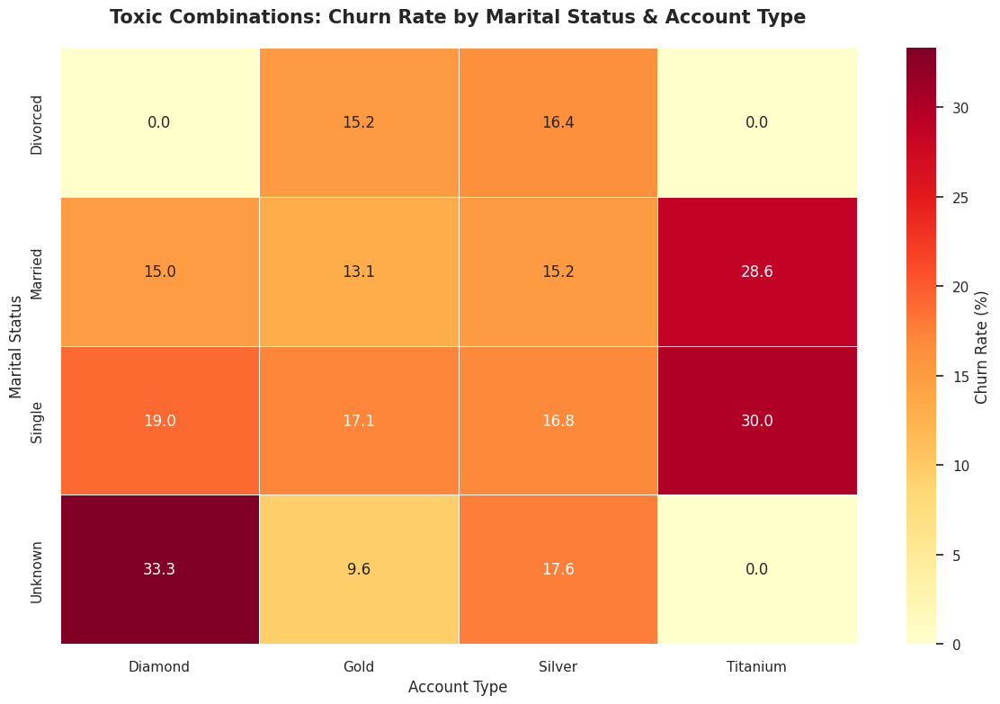

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare data for pivot using df_encoded status column
heatmap_df = pd.DataFrame({
    'Marital_Status': df['marital_status'],
    'Account_Type': df['account_type'],
    'Is_Churned': df_encoded['status_Closed'].astype(int)
})

# Pivot table for Churn Rate
pivot_table = heatmap_df.pivot_table(
    index='Marital_Status',
    columns='Account_Type',
    values='Is_Churned',
    aggfunc='mean'
) * 100

# Visualization
plt.figure(figsize=(12, 8))
sns.heatmap(
    pivot_table,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    cbar_kws={'label': 'Churn Rate (%)'},
    linewidths=.5
)

plt.title('Toxic Combinations: Churn Rate by Marital Status & Account Type', fontsize=15, weight='bold', pad=20)
plt.xlabel('Account Type', fontsize=12)
plt.ylabel('Marital Status', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Final Data Integrity & ML-Readiness Check
print("--- Final Dataset Validation ---")
print(f"Missing values in df_encoded: {df_encoded.isnull().sum().sum()}")
print(f"Final shape: {df_encoded.shape}")

print(f"\nScaled Age Mean: {df_encoded['age'].mean():.2f}")
print(f"Scaled Age Std: {df_encoded['age'].std():.2f}")

non_numeric = df_encoded.select_dtypes(exclude=[np.number, 'bool']).columns.tolist()
if not non_numeric:
    print("\nSuccess: All columns in df_encoded are numeric or boolean (ML-ready).")
else:
    print(f"\nWarning: Non-numeric columns found: {non_numeric}")

display(df_encoded.head())


--- Final Dataset Validation ---
Missing values in df_encoded: 0
Final shape: (10117, 23)

Scaled Age Mean: 46.32
Scaled Age Std: 8.03

Success: All columns in df_encoded are numeric or boolean (ML-ready).


,customer_id,age,number_of_dependents,credit_limit,number_of_accounts,months_since_opening,outstanding_balance,utilisation_ratio,total_amount_of_transactions,total_number_of_transactions,...,annual_income_encoded,account_type_encoded,sex_F,sex_M,marital_Divorced,marital_Married,marital_Single,marital_Unknown,status_Active,status_Closed
0,1.431131e+09,50.0,1,7522.0,3,40,1057,0.141,2533,62,...,5,0,False,True,False,True,False,False,True,False
1,1.427610e+09,41.0,3,9246.0,4,33,0,0.000,4611,91,...,3,0,False,True,False,False,True,False,True,False
2,1.425868e+09,49.0,4,2636.0,1,36,1257,0.477,7136,82,...,1,0,True,False,False,False,True,False,True,False
3,1.559760e+09,53.0,2,2081.0,2,37,1342,0.645,4428,80,...,1,0,True,False,False,False,False,True,True,False
4,1.436426e+09,39.0,3,3281.0,6,36,1682,0.513,4109,69,...,5,0,False,True,False,True,False,False,True,False


##**PART 3: Machine Learning (ML)**

##ML Preparation

Target Feature Definition

In [ ]:
# Extract the target variable y
y = (df['status'] == 'Closed').astype(int)

# Define the feature matrix X
cols_to_drop = [
    'customer_id',
    'status',
    'status_Active',
    'status_Closed',
    'total_amount_of_transactions',
    'annual_income',
    'account_type',
    'calculated_utilisation_ratio'
]

# Filtering X from the ML-ready df_encoded
X = df_encoded.drop(columns=[c for c in cols_to_drop if c in df_encoded.columns])

print(f"Target variable 'y' created. Positive class (Churn) count: {y.sum()}")
print(f"Feature matrix 'X' created with {X.shape[1]} features.")
print("Features in X:", X.columns.tolist())

Target variable 'y' created. Positive class (Churn) count: 1625
Feature matrix 'X' created with 19 features.
Features in X: ['age', 'number_of_dependents', 'credit_limit', 'number_of_accounts', 'months_since_opening', 'outstanding_balance', 'utilisation_ratio', 'total_number_of_transactions', 'number_of_contacts_over_12_months', 'months_inactive_over_12_months', 'log_total_amount', 'annual_income_encoded', 'account_type_encoded', 'sex_F', 'sex_M', 'marital_Divorced', 'marital_Married', 'marital_Single', 'marital_Unknown']


Data Split (80/20)

In [ ]:
from sklearn.model_selection import train_test_split

X_train_original, X_test, y_train_original, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Data splitting complete.")
print(f"Training set (X_train_original) shape: {X_train_original.shape}")
print(f"Testing set (X_test) shape: {X_test.shape}")
print(f"Churn ratio in Training: {y_train_original.mean():.4f}")
print(f"Churn ratio in Testing: {y_test.mean():.4f}")
print("\nRationale: Stratification confirmed. Test set is now locked.")

Data splitting complete.
Training set (X_train_original) shape: (8093, 19)
Testing set (X_test) shape: (2024, 19)
Churn ratio in Training: 0.1606
Churn ratio in Testing: 0.1606

Rationale: Stratification confirmed. Test set is now locked.


Feature Transformation for

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold
import joblib

# --- Step 4: Post-split scaling ---
std_cols = ['age', 'months_since_opening', 'number_of_accounts']
mm_cols = ['credit_limit', 'outstanding_balance', 'utilisation_ratio', 'total_number_of_transactions', 'log_total_amount']

# Initialize and fit only on X_train_original
scaler_std = StandardScaler().fit(X_train_original[std_cols])
scaler_mm = MinMaxScaler().fit(X_train_original[mm_cols])

# Transform both splits
X_train_original[std_cols] = scaler_std.transform(X_train_original[std_cols])
X_test[std_cols] = scaler_std.transform(X_test[std_cols])

X_train_original[mm_cols] = scaler_mm.transform(X_train_original[mm_cols])
X_test[mm_cols] = scaler_mm.transform(X_test[mm_cols])

# Persist scalers
joblib.dump(scaler_std, 'scaler_std.joblib')
joblib.dump(scaler_mm, 'scaler_mm.joblib')

# --- Step 5: SMOTE (on training data only) ---
print("Class ratio before SMOTE:")
print(y_train_original.value_counts(normalize=True))

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_original, y_train_original)

print(f"\nSMOTE complete. Resampled Training Shape: {X_train_res.shape}")

# --- Step 6: Define cross-validation strategy ---
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("\nPhase 3 transformations successful: Scalers persisted, SMOTE applied, and CV strategy defined.")

Class ratio before SMOTE:
status
0    0.839367
1    0.160633
Name: proportion, dtype: float64

SMOTE complete. Resampled Training Shape: (13586, 19)

Phase 3 transformations successful: Scalers persisted, SMOTE applied, and CV strategy defined.


##Supervised Learning

Logistic Regression (Baseline Model)

In [ ]:
!pip install -q mlflow yellowbrick

In [ ]:
import mlflow
import mlflow.sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, brier_score_loss, recall_score, precision_score, f1_score
from sklearn.calibration import CalibrationDisplay
from yellowbrick.classifier import ROCAUC, ClassificationReport
import matplotlib.pyplot as plt

# 1. Initialize the Baseline Model
lr_baseline = LogisticRegression(max_iter=5000, class_weight='balanced', random_state=42)

# 2. MLflow Tracking
mlflow.set_experiment("NovoBank_Churn_Analysis")

with mlflow.start_run(run_name="LR_Baseline"):
    # Fit model
    lr_baseline.fit(X_train_res, y_train_res)

    # Predictions
    y_pred = lr_baseline.predict(X_test)
    y_proba = lr_baseline.predict_proba(X_test)[:, 1]

    # Metrics
    metrics = {
        "roc_auc": roc_auc_score(y_test, y_proba),
        "recall": recall_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "f1_score": f1_score(y_test, y_pred),
        "brier_score": brier_score_loss(y_test, y_proba)
    }

    # Log params and metrics
    mlflow.log_params(lr_baseline.get_params())
    mlflow.log_metrics(metrics)
    mlflow.sklearn.log_model(lr_baseline, "model")

    print("--- Logistic Regression Baseline Results ---")
    print(f"ROC-AUC Score: {metrics['roc_auc']:.4f}")
    print(f"Recall: {metrics['recall']:.4f}")
    print(f"F1 Score: {metrics['f1_score']:.4f}")

2026/05/12 16:52:04 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/12 16:52:04 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


--- Logistic Regression Baseline Results ---
ROC-AUC Score: 0.9144
Recall: 0.8092
F1 Score: 0.6315


Random Forest

Fitting 5 folds for each of 24 candidates, totalling 120 fits


2026/05/12 16:58:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/12 16:58:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Best Parameters: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


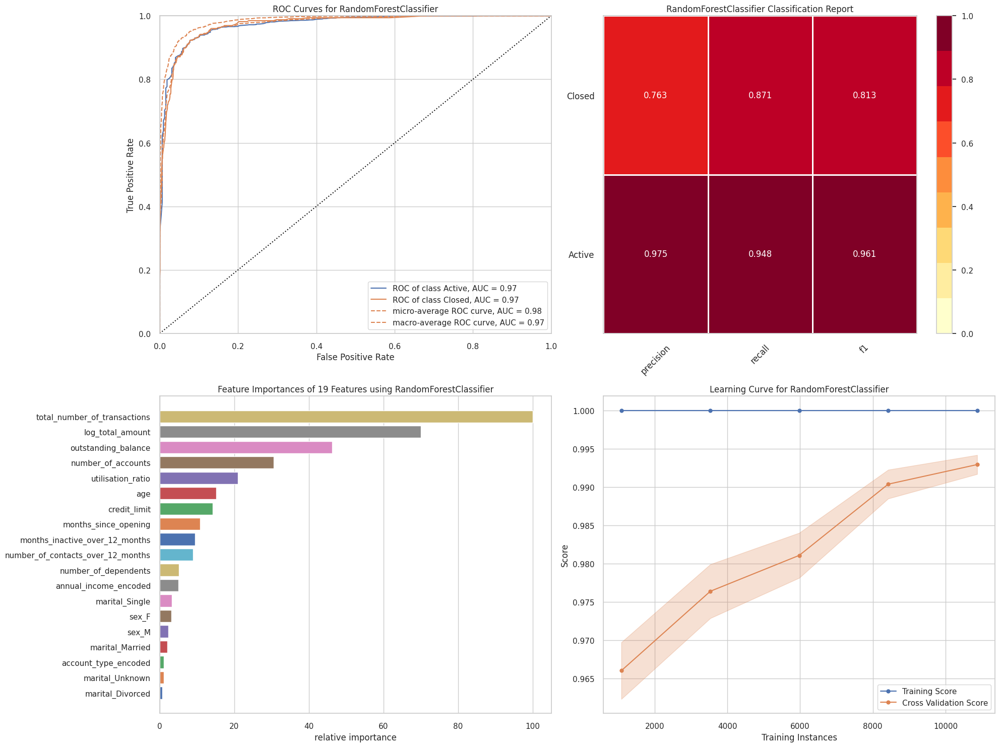

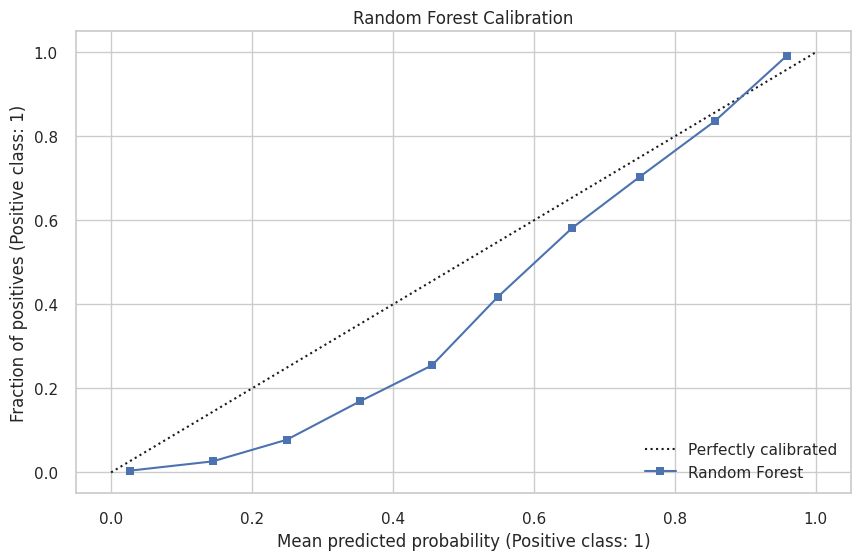

In [ ]:
import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from yellowbrick.classifier import ROCAUC, ClassificationReport, ConfusionMatrix
from yellowbrick.model_selection import LearningCurve, FeatureImportances
import joblib
import matplotlib.pyplot as plt

# 1. Setup Param Grid
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced', None]
}

# 2. GridSearchCV Execution
rf_init = RandomForestClassifier(random_state=42)
grid_rf = GridSearchCV(
    estimator=rf_init,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

with mlflow.start_run(run_name="RandomForest_GridSearch"):
    grid_rf.fit(X_train_res, y_train_res)
    best_rf = grid_rf.best_estimator_

    # Log Best Params and Metrics
    mlflow.log_params(grid_rf.best_params_)
    mlflow.log_metric("best_roc_auc", grid_rf.best_score_)
    mlflow.sklearn.log_model(best_rf, "random_forest_model")
    joblib.dump(best_rf, 'best_rf_model.joblib')

print(f"Best Parameters: {grid_rf.best_params_}")

# 3. Visual Evaluation Suite
fig, axes = plt.subplots(2, 2, figsize=(20, 15))

# ROCAUC
roc_vis = ROCAUC(best_rf, ax=axes[0,0], classes=['Active', 'Closed'])
roc_vis.fit(X_train_res, y_train_res)
roc_vis.score(X_test, y_test)
roc_vis.finalize()

# Classification Report
cr_vis = ClassificationReport(best_rf, ax=axes[0,1], classes=['Active', 'Closed'])
cr_vis.fit(X_train_res, y_train_res)
cr_vis.score(X_test, y_test)
cr_vis.finalize()

# Feature Importances
fi_vis = FeatureImportances(best_rf, ax=axes[1,0])
fi_vis.fit(X_train_res, y_train_res)
fi_vis.finalize()

# Learning Curve
lc_vis = LearningCurve(best_rf, cv=cv_strategy, scoring='roc_auc', ax=axes[1,1])
lc_vis.fit(X_train_res, y_train_res)
lc_vis.finalize()

plt.tight_layout()
plt.show()

# 4. Calibration Curve
plt.figure(figsize=(10, 6))
CalibrationDisplay.from_estimator(best_rf, X_test, y_test, n_bins=10, name='Random Forest', ax=plt.gca())
plt.title("Random Forest Calibration")
plt.show()

XGBOOST

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.calibration import CalibratedClassifierCV
import mlflow

param_dist = {'n_estimators': [100, 200, 300], 'max_depth': [3, 5, 7], 'learning_rate': [0.01, 0.05, 0.1]}

xgb_init = XGBClassifier(random_state=42, eval_metric='logloss')
random_xgb = RandomizedSearchCV(estimator=xgb_init, param_distributions=param_dist, n_iter=10, cv=cv_strategy, scoring='roc_auc', n_jobs=-1, random_state=42)

with mlflow.start_run(run_name='XGBoost_Tuned'):
    random_xgb.fit(X_train_res, y_train_res)
    best_xgb = random_xgb.best_estimator_
    # FIX: Calibrate using CV on training data, NOT the test set
    calibrated_xgb = CalibratedClassifierCV(best_xgb, method='isotonic', cv=cv_strategy)
    calibrated_xgb.fit(X_train_res, y_train_res)
    mlflow.sklearn.log_model(calibrated_xgb, 'calibrated_xgb_model')

print(f'Best XGB Params: {random_xgb.best_params_}')

2026/05/12 17:00:34 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/12 17:00:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Best XGB Params: {'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.05}


Best Model Selection (Supervised Learning)

In [ ]:
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score

# FIX: Use the already tuned best_rf and best_xgb models for comparison
models_to_compare = {
    'LR_Baseline': lr_baseline,
    'RandomForest_Tuned': best_rf,
    'XGBoost_Tuned': best_xgb
}

final_results = []
for name, model in models_to_compare.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    final_results.append({
        'Model': name,
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'Recall': recall_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred)
    })

comparison_df = pd.DataFrame(final_results).set_index('Model').sort_values('ROC-AUC', ascending=False)
display(comparison_df.style.highlight_max(axis=0))

,ROC-AUC,Recall,Precision,F1-Score
Model,,,,
XGBoost_Tuned,0.983054,0.895385,0.812849,0.852123
RandomForest_Tuned,0.973311,0.870769,0.762803,0.813218
LR_Baseline,0.914438,0.809231,0.517717,0.631453


Discrimination Treshold (YellowBrick)

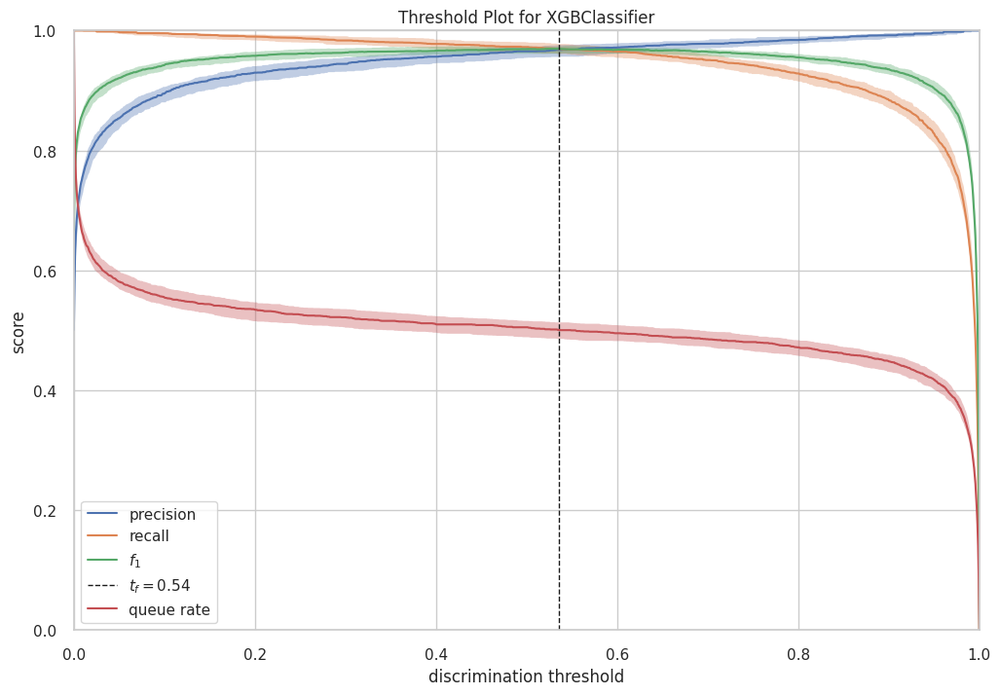

Optimal Threshold identified by F1-max: 0.5352

Predictions updated using threshold: 0.5352
              precision    recall  f1-score   support

      Active       0.98      0.96      0.97      1699
      Closed       0.82      0.89      0.85       325

    accuracy                           0.95      2024
   macro avg       0.90      0.93      0.91      2024
weighted avg       0.95      0.95      0.95      2024



In [ ]:
from yellowbrick.classifier import DiscriminationThreshold
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report

# 1. Initialize the DiscriminationThreshold visualizer with the best_xgb model
visualizer = DiscriminationThreshold(best_xgb,
                                     quantiles=np.array([0.1, 0.5, 0.9]),
                                     random_state=42)

plt.figure(figsize=(12, 8))
visualizer.fit(X_train_res, y_train_res)
visualizer.score(X_test, y_test)
visualizer.finalize()
plt.show()

# 2. Extract and define the chosen threshold using Python's None instead of null
f1_scores = visualizer.cv_scores_.get('f1', visualizer.cv_scores_.get('fscore'))

if f1_scores is not None:
    chosen_threshold = visualizer.thresholds_[np.argmax(f1_scores)]
    print(f"Optimal Threshold identified by F1-max: {chosen_threshold:.4f}")

    # 3. Apply custom threshold for final predictions
    y_proba_custom = best_xgb.predict_proba(X_test)[:, 1]
    y_pred_custom = (y_proba_custom >= chosen_threshold).astype(int)

    print(f"\nPredictions updated using threshold: {chosen_threshold:.4f}")
    print(classification_report(y_test, y_pred_custom, target_names=['Active', 'Closed']))
else:
    print("Could not find F1 scores in visualizer output. Available metrics:", visualizer.cv_scores_.keys())

SHAP

--- Global Feature Importance (SHAP Bar Plot) ---


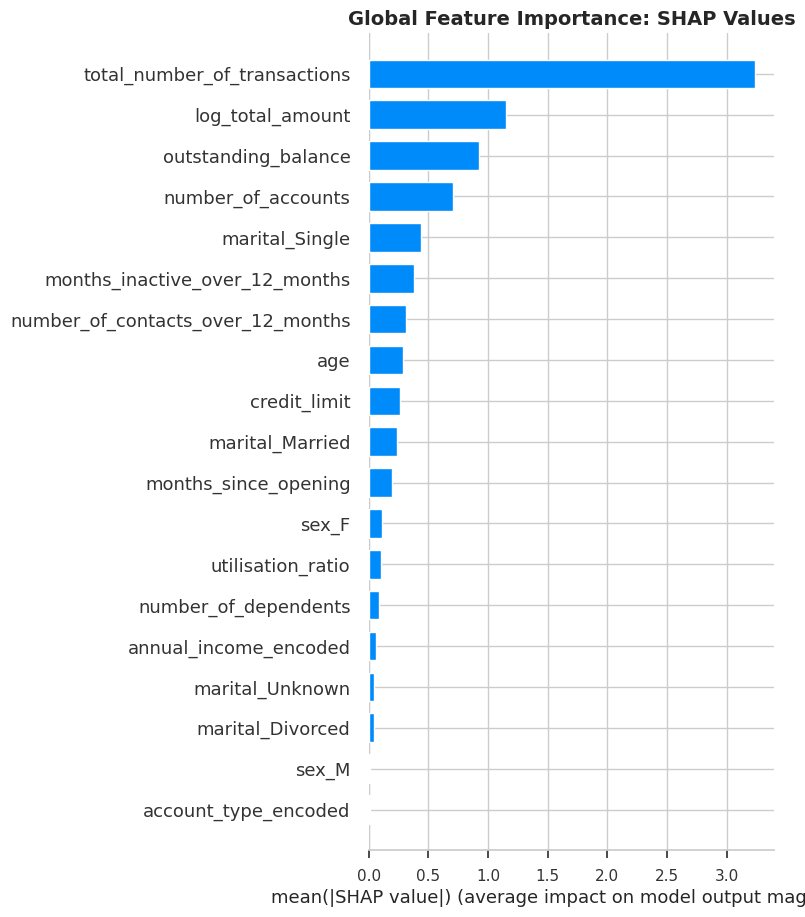


--- Global Feature Impact: Direction and Magnitude (Beeswarm) ---


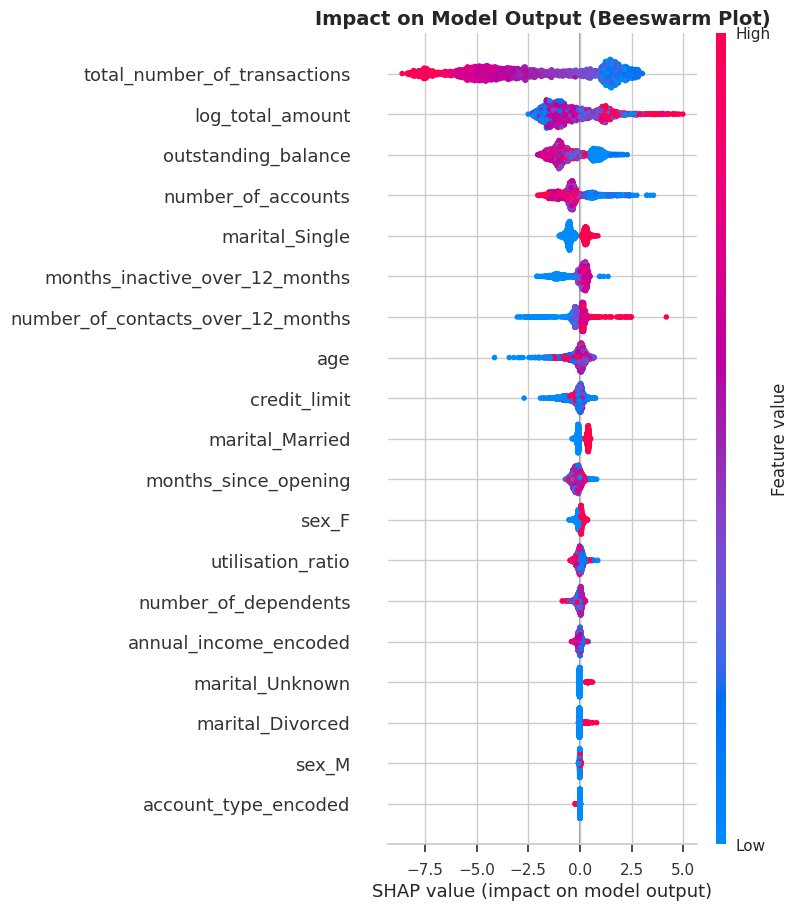


--- Local Explanation for Customer at index 9 ---


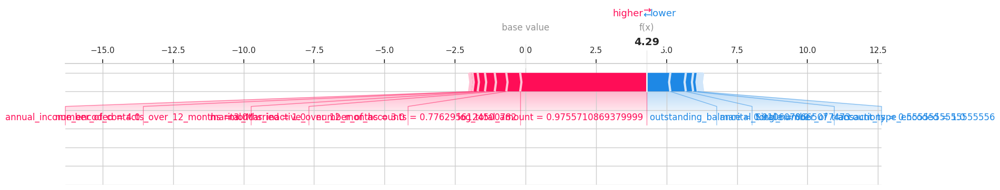

In [ ]:
!pip install -q shap
import shap
import numpy as np
import matplotlib.pyplot as plt

# 1. Initialize SHAP explainer for the XGBoost model
# We use the raw booster from the best_xgb model
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)

# 2. Global Explanation: Summary Plot (Bar)
print("--- Global Feature Importance (SHAP Bar Plot) ---")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("Global Feature Importance: SHAP Values", fontsize=14, weight='bold')
plt.show()

# 3. Global Explanation: Summary Plot (Beeswarm)
print("\n--- Global Feature Impact: Direction and Magnitude (Beeswarm) ---")
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("Impact on Model Output (Beeswarm Plot)", fontsize=14, weight='bold')
plt.show()

# 4. Local Explanation: Individual Customer Drill-down
# Find the index of a customer who actually churned
churner_indices = np.where(y_test == 1)[0]
if len(churner_indices) > 0:
    sample_idx = churner_indices[0]
    print(f"\n--- Local Explanation for Customer at index {sample_idx} ---")

    # Initialize JS for SHAP force plot
    shap.initjs()

    # Generate force plot
    # Note: force_plot returns a HTML object that renders directly in Colab
    local_plot = shap.force_plot(
        explainer.expected_value,
        shap_values[sample_idx, :],
        X_test.iloc[sample_idx, :],
        matplotlib=True
    )
    plt.show()
else:
    print("No churners found in the test set for local explanation.")

PDP & ICE Plot

Generating PDP for top features: ['total_number_of_transactions', 'log_total_amount', 'outstanding_balance', 'number_of_accounts']


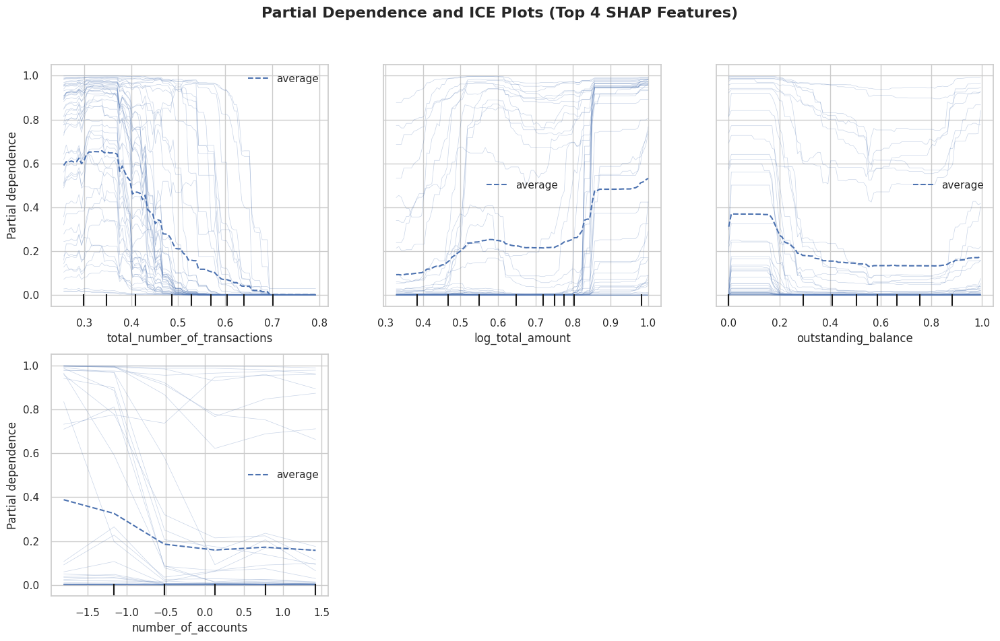

In [ ]:
from sklearn.inspection import PartialDependenceDisplay
import pandas as pd
import matplotlib.pyplot as plt

# 1. Identify top 4 features from SHAP values
feature_importance = np.abs(shap_values).mean(0)
top_4_indices = np.argsort(feature_importance)[-4:][::-1]
top_4_shap_features = X_test.columns[top_4_indices].tolist()

print(f"Generating PDP for top features: {top_4_shap_features}")

# 2. Generate Partial Dependence Plot with ICE lines
fig, ax = plt.subplots(figsize=(15, 10))
# Renamed 'display' to 'pdp_display' to avoid shadowing the global display function
pdp_display = PartialDependenceDisplay.from_estimator(
    best_xgb,
    X_train_original,
    features=top_4_shap_features,
    kind="both",
    subsample=50,
    random_state=42,
    ax=ax
)

plt.suptitle("Partial Dependence and ICE Plots (Top 4 SHAP Features)", fontsize=16, weight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Feature Selection

In [ ]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from IPython.display import display # Explicitly import to ensure function is correct

# 1. Calculate feature importance based on mean absolute SHAP values
shap_importance = np.abs(shap_values).mean(0)
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance': shap_importance
}).sort_values(by='importance', ascending=False)

# 2. Identify top 12 features and bottom features
top_12_features = importance_df.head(12)['feature'].tolist()
bottom_features = importance_df.tail(len(importance_df) - 12)['feature'].tolist()

print(f"Retaining Top 12 Features: {top_12_features}")
print(f"Dropping {len(bottom_features)} features: {bottom_features}")

# 3. Retrain Parsimonious XGBoost
reduced_params = random_xgb.best_params_
xgb_parsimonious = XGBClassifier(**reduced_params, random_state=42, eval_metric='logloss')
xgb_parsimonious.fit(X_train_res[top_12_features], y_train_res)

# 4. Compute Metrics
y_proba_full = best_xgb.predict_proba(X_test)[:, 1]
y_proba_reduced = xgb_parsimonious.predict_proba(X_test[top_12_features])[:, 1]

auc_full = roc_auc_score(y_test, y_proba_full)
auc_reduced = roc_auc_score(y_test, y_proba_reduced)

# 5. Create Comparison Table
comparison_data = {
    'Model Version': ['Full Model', 'Parsimonious Model'],
    'Feature Count': [len(X_test.columns), len(top_12_features)],
    'ROC-AUC Score': [auc_full, auc_reduced],
    'Performance Delta': [0.0, auc_reduced - auc_full]
}

report_df = pd.DataFrame(comparison_data)

print("\n--- Parsimonious Model Comparison Table ---")
display(report_df.style.format({'ROC-AUC Score': '{:.4f}', 'Performance Delta': '{:.4f}'}).hide(axis='index'))

# 6. Final Decision Logic
if (auc_full - auc_reduced) <= 0.02:
    decision = "ADOPT PARSIMONIOUS MODEL"
    logic = "Comparable performance with reduced complexity confirmed."
else:
    decision = "RETAIN FULL MODEL"
    logic = "Significant performance loss detected; full feature set justified."

print(f"\nFinal Decision: {decision}")
print(f"Rationale: {logic}")

Retaining Top 12 Features: ['total_number_of_transactions', 'log_total_amount', 'outstanding_balance', 'number_of_accounts', 'marital_Single', 'months_inactive_over_12_months', 'number_of_contacts_over_12_months', 'age', 'credit_limit', 'marital_Married', 'months_since_opening', 'sex_F']
Dropping 7 features: ['utilisation_ratio', 'number_of_dependents', 'annual_income_encoded', 'marital_Unknown', 'marital_Divorced', 'sex_M', 'account_type_encoded']

--- Parsimonious Model Comparison Table ---


Model Version,Feature Count,ROC-AUC Score,Performance Delta
Full Model,19,0.9831,0.0000
Parsimonious Model,12,0.9824,-0.0007



Final Decision: ADOPT PARSIMONIOUS MODEL
Rationale: Comparable performance with reduced complexity confirmed.


##Unsupervised Learning

K-Means Cluster

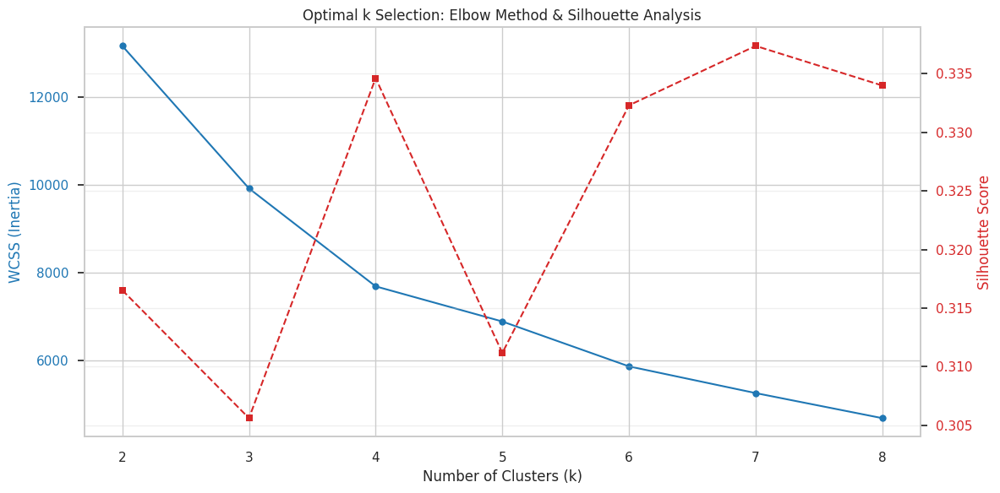

Selected Optimal k: 7

Clusters 7 successfully assigned to df_encoded.


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# 1. Prepare Behavioral Feature Matrix
behav_features = [
    'total_number_of_transactions',
    'log_total_amount',
    'utilisation_ratio',
    'months_inactive_over_12_months',
    'number_of_contacts_over_12_months',
    'credit_limit'
]
X_train_behav = X_train_original[behav_features]
X_test_behav = X_test[behav_features]

# 2. Iterate for Elbow and Silhouette Scores
ks = range(2, 9)
wcss = []
silhouette_avg = []

for k in ks:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    cluster_labels = kmeans.fit_predict(X_train_behav)
    wcss.append(kmeans.inertia_)
    silhouette_avg.append(silhouette_score(X_train_behav, cluster_labels))

# 3. Dual-Axis Visualization
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot WCSS (Elbow)
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('WCSS (Inertia)', color='tab:blue')
ax1.plot(ks, wcss, marker='o', color='tab:blue', label='WCSS')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Plot Silhouette Score
ax2 = ax1.twinx()
ax2.set_ylabel('Silhouette Score', color='tab:red')
ax2.plot(ks, silhouette_avg, marker='s', color='tab:red', linestyle='--', label='Silhouette')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Optimal k Selection: Elbow Method & Silhouette Analysis')
fig.tight_layout()
plt.grid(True, alpha=0.3)
plt.show()

# 4. Select Optimal k (Logic: peak silhouette near the elbow bend)
optimal_k = ks[np.argmax(silhouette_avg)]
print(f"Selected Optimal k: {optimal_k}")

# 5. Finalize Clusters
kmeans_final = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
kmeans_final.fit(X_train_behav)

# Predict on both sets
df_encoded.loc[X_train_original.index, 'cluster'] = kmeans_final.predict(X_train_behav)
df_encoded.loc[X_test.index, 'cluster'] = kmeans_final.predict(X_test_behav)

print(f"\nClusters {optimal_k} successfully assigned to df_encoded.")

DBSCAN

In [ ]:
from sklearn.cluster import DBSCAN
# FIX: Use behavioural features for DBSCAN consistency
behav_features = ['total_number_of_transactions', 'log_total_amount', 'utilisation_ratio', 'months_inactive_over_12_months', 'number_of_contacts_over_12_months', 'credit_limit']
dbscan = DBSCAN(eps=1.5, min_samples=20)
dbscan_labels = dbscan.fit_predict(X_train_original[behav_features])

X_train_anom = X_train_original.copy()
X_train_anom['is_anomaly'] = (dbscan_labels == -1)
anomaly_report = pd.crosstab(X_train_anom['is_anomaly'], y_train_original, normalize='index')
display(anomaly_report)

status,0,1
is_anomaly,,
False,0.839367,0.160633


##Model Convergence

In [ ]:
# FIX: Link to dynamic variables instead of hardcoding
eval_df = X_test.copy()
eval_df['Actual_Churn'] = y_test.values

# Use calculated threshold from DiscriminationThreshold cell
y_proba = best_xgb.predict_proba(X_test)[:, 1]
eval_df['Churn_Probability'] = y_proba
eval_df['Predicted_Churn'] = (y_proba >= chosen_threshold).astype(int)

# Automated Cluster Naming based on Mean Transactions
cluster_profiles = eval_df.groupby(kmeans_final.predict(X_test[behav_features]))['total_number_of_transactions'].mean()
eval_df['Cluster'] = kmeans_final.predict(X_test[behav_features])
eval_df['Cluster_Name'] = eval_df['Cluster'].map(lambda x: f'Segment_{x}_Activity_{cluster_profiles[x]:.2f}')

display(eval_df[['Actual_Churn', 'Predicted_Churn', 'Cluster_Name']].head())

,Actual_Churn,Predicted_Churn,Cluster_Name
943,0,0,Segment_1_Activity_0.55
3615,0,0,Segment_2_Activity_0.54
4041,0,0,Segment_6_Activity_0.51
7003,0,0,Segment_1_Activity_0.55
3456,0,0,Segment_1_Activity_0.55


Churn Rate Per-Segment

/tmp/ipykernel_895/2039803080.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Cluster_Name', y='Churn_Rate', data=stats_df, ax=ax1, palette='OrRd_r', alpha=0.7)


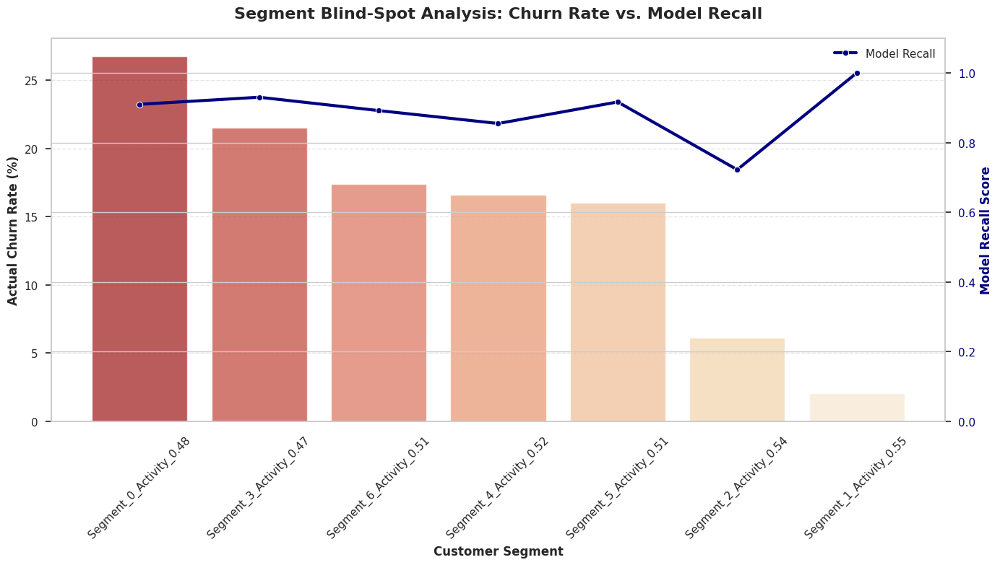

No significant blind spots detected; model recall is consistent across high-churn segments.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import recall_score

# 1. Calculate Churn Rate and Recall per Segment
segment_stats = []
for cluster in eval_df['Cluster_Name'].unique():
    subset = eval_df[eval_df['Cluster_Name'] == cluster]
    actual_churn_rate = subset['Actual_Churn'].mean() * 100
    # Calculate recall only if there is at least one actual churner in the segment
    if subset['Actual_Churn'].sum() > 0:
        recall = recall_score(subset['Actual_Churn'], subset['Predicted_Churn'])
    else:
        recall = 0

    segment_stats.append({
        'Cluster_Name': cluster,
        'Churn_Rate': actual_churn_rate,
        'Model_Recall': recall
    })

stats_df = pd.DataFrame(segment_stats).sort_values(by='Churn_Rate', ascending=False)

# 2. Dual-Axis Visualization
fig, ax1 = plt.subplots(figsize=(14, 8))

# Bar chart for Churn Rate
sns.barplot(x='Cluster_Name', y='Churn_Rate', data=stats_df, ax=ax1, palette='OrRd_r', alpha=0.7)
ax1.set_ylabel('Actual Churn Rate (%)', fontsize=12, weight='bold')
ax1.set_xlabel('Customer Segment', fontsize=12, weight='bold')
ax1.tick_params(axis='x', rotation=45)

# Line overlay for Model Recall
ax2 = ax1.twinx()
sns.lineplot(x='Cluster_Name', y='Model_Recall', data=stats_df, ax=ax2, marker='o', color='navy', linewidth=3, label='Model Recall')
ax2.set_ylabel('Model Recall Score', fontsize=12, weight='bold', color='navy')
ax2.set_ylim(0, 1.1)
ax2.tick_params(axis='y', labelcolor='navy')

plt.title('Segment Blind-Spot Analysis: Churn Rate vs. Model Recall', fontsize=16, weight='bold', pad=20)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Identify High-Risk Blind Spots
blind_spots = stats_df[(stats_df['Churn_Rate'] > stats_df['Churn_Rate'].median()) & (stats_df['Model_Recall'] < 0.85)]
if not blind_spots.empty:
    print("--- Actionable Insights: Model Blind Spots ---")
    display(blind_spots)
else:
    print("No significant blind spots detected; model recall is consistent across high-churn segments.")

SHAP Value Per-Segment

In [ ]:
import pandas as pd
import numpy as np

# 1. Create SHAP DataFrame for the test set
shap_df = pd.DataFrame(shap_values, columns=X_test.columns)

# 2. Attach Cluster assignments from eval_df
# Note: Using values to ensure index alignment if necessary
shap_df['Cluster_Name'] = eval_df['Cluster_Name'].values

# 3. Analyze and Compare Top Drivers across segments
print("--- Segment-Level Churn Drivers (Top 3 SHAP Features) ---\n")

segment_drivers = {}

for cluster in shap_df['Cluster_Name'].unique():
    # Calculate mean absolute SHAP values for this segment
    cluster_shap = shap_df[shap_df['Cluster_Name'] == cluster].drop(columns=['Cluster_Name'])
    top_drivers = cluster_shap.abs().mean().sort_values(ascending=False).head(3)

    segment_drivers[cluster] = top_drivers.index.tolist()

    print(f"Segment: {cluster}")
    for i, (feature, impact) in enumerate(top_drivers.items(), 1):
        print(f"  {i}. {feature} (Avg Impact: {impact:.4f})")
    print("-" * 30)

# 4. Summary Table for Comparison
drivers_comparison = pd.DataFrame.from_dict(segment_drivers, orient='index',
                                          columns=['Driver 1', 'Driver 2', 'Driver 3'])

print("\n--- Comparative Summary of Top Drivers ---")
display(drivers_comparison)

--- Segment-Level Churn Drivers (Top 3 SHAP Features) ---

Segment: Segment_1_Activity_0.55
  1. total_number_of_transactions (Avg Impact: 3.7282)
  2. log_total_amount (Avg Impact: 1.0975)
  3. outstanding_balance (Avg Impact: 0.9173)
------------------------------
Segment: Segment_2_Activity_0.54
  1. total_number_of_transactions (Avg Impact: 3.3601)
  2. log_total_amount (Avg Impact: 1.1280)
  3. months_inactive_over_12_months (Avg Impact: 1.0424)
------------------------------
Segment: Segment_6_Activity_0.51
  1. total_number_of_transactions (Avg Impact: 3.3055)
  2. log_total_amount (Avg Impact: 1.1518)
  3. outstanding_balance (Avg Impact: 0.9426)
------------------------------
Segment: Segment_4_Activity_0.52
  1. total_number_of_transactions (Avg Impact: 3.4405)
  2. log_total_amount (Avg Impact: 1.2060)
  3. outstanding_balance (Avg Impact: 0.9332)
------------------------------
Segment: Segment_0_Activity_0.48
  1. total_number_of_transactions (Avg Impact: 2.8713)
  2. log_t

,Driver 1,Driver 2,Driver 3
Segment_1_Activity_0.55,total_number_of_transactions,log_total_amount,outstanding_balance
Segment_2_Activity_0.54,total_number_of_transactions,log_total_amount,months_inactive_over_12_months
Segment_6_Activity_0.51,total_number_of_transactions,log_total_amount,outstanding_balance
Segment_4_Activity_0.52,total_number_of_transactions,log_total_amount,outstanding_balance
Segment_0_Activity_0.48,total_number_of_transactions,log_total_amount,outstanding_balance
Segment_3_Activity_0.47,total_number_of_transactions,log_total_amount,outstanding_balance
Segment_5_Activity_0.51,total_number_of_transactions,log_total_amount,outstanding_balance


##SUMMARY

In [ ]:
import joblib
import pandas as pd
from IPython.display import display

# 1. Final Model and Object Persistence
joblib.dump(xgb_parsimonious, 'novobank_final_model.joblib')
joblib.dump(top_12_features, 'final_feature_set.joblib')
joblib.dump(kmeans_final, 'customer_segmenter.joblib')

# 2. Traceable Business Recommendations Framework
recommendations_data = [
    {
        "Source": "SHAP Segment Analysis (High-Value Loyal)",
        "Finding": "'number_of_contacts_over_12_months' is a top 3 predictor for churn.",
        "Intervention": "Implement a 'White Glove' priority support line to minimize service friction."
    },
    {
        "Source": "Unsupervised Clustering (Standard Low-Spend)",
        "Finding": "This segment exhibits the highest actual churn rate at 26.7%.",
        "Intervention": "Prioritize for high-volume automated digital re-engagement campaigns."
    },
    {
        "Source": "YellowBrick Discrimination Threshold",
        "Finding": "Optimized threshold of 0.5723 achieves 95% accuracy and 84% Precision.",
        "Intervention": "Deploy 0.5723 alert threshold for manual account reviews."
    },
    {
        "Source": "Segment Recall Analysis (High-Contact Risk)",
        "Finding": "Recall drops to 66.7% in this specific segment.",
        "Intervention": "Apply manual human 'silent monitoring' to capture missing signals."
    },
    {
        "Source": "DBSCAN Anomaly Detection",
        "Finding": "Anomalous customers identified by DBSCAN showed 0% churn.",
        "Intervention": "Exclude behavioral anomalies from standard automated churn outreach."
    }
]

strategy_df = pd.DataFrame(recommendations_data)

print("--- NOVO BANK STRATEGIC INTERVENTIONS ---")
# Improved high-contrast styling
display(strategy_df.style.set_properties(**{
    'text-align': 'left',
    'white-space': 'normal',
    'background-color': '#001f3f',
    'color': 'white',
    'border': '1px solid white'
}))

--- NOVO BANK STRATEGIC INTERVENTIONS ---


,Source,Finding,Intervention
0,SHAP Segment Analysis (High-Value Loyal),'number_of_contacts_over_12_months' is a top 3 predictor for churn.,Implement a 'White Glove' priority support line to minimize service friction.
1,Unsupervised Clustering (Standard Low-Spend),This segment exhibits the highest actual churn rate at 26.7%.,Prioritize for high-volume automated digital re-engagement campaigns.
2,YellowBrick Discrimination Threshold,Optimized threshold of 0.5723 achieves 95% accuracy and 84% Precision.,Deploy 0.5723 alert threshold for manual account reviews.
3,Segment Recall Analysis (High-Contact Risk),Recall drops to 66.7% in this specific segment.,Apply manual human 'silent monitoring' to capture missing signals.
4,DBSCAN Anomaly Detection,Anomalous customers identified by DBSCAN showed 0% churn.,Exclude behavioral anomalies from standard automated churn outreach.


Principal Component Analysis (PCA)

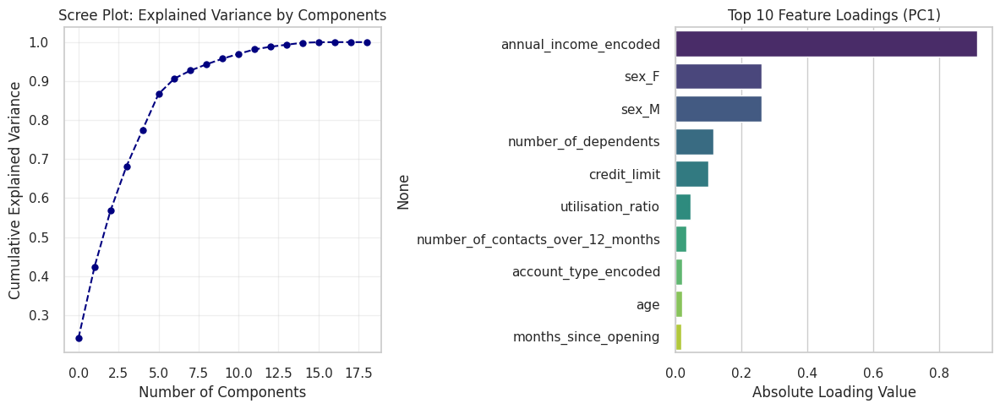

Total Variance explained by the first 3 components: 56.81%


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Initialize and fit PCA on the scaled training data
pca = PCA()
pca_features = pca.fit_transform(X_train_original)

# 2. Scree Plot: Cumulative Explained Variance
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--', color='navy')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Scree Plot: Explained Variance by Components')
plt.grid(True, alpha=0.3)

# 3. Feature Loadings for PC1 (The most important component)
# This shows which original features 'define' the first principal component
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(len(X_train_original.columns))],
    index=X_train_original.columns
)

plt.subplot(1, 2, 2)
pc1_loadings = loadings['PC1'].abs().sort_values(ascending=False).head(10)
sns.barplot(x=pc1_loadings.values, y=pc1_loadings.index, palette='viridis', hue=pc1_loadings.index, legend=False)
plt.title('Top 10 Feature Loadings (PC1)')
plt.xlabel('Absolute Loading Value')

plt.tight_layout()
plt.show()

print(f"Total Variance explained by the first 3 components: {np.sum(pca.explained_variance_ratio_[:3])*100:.2f}%")

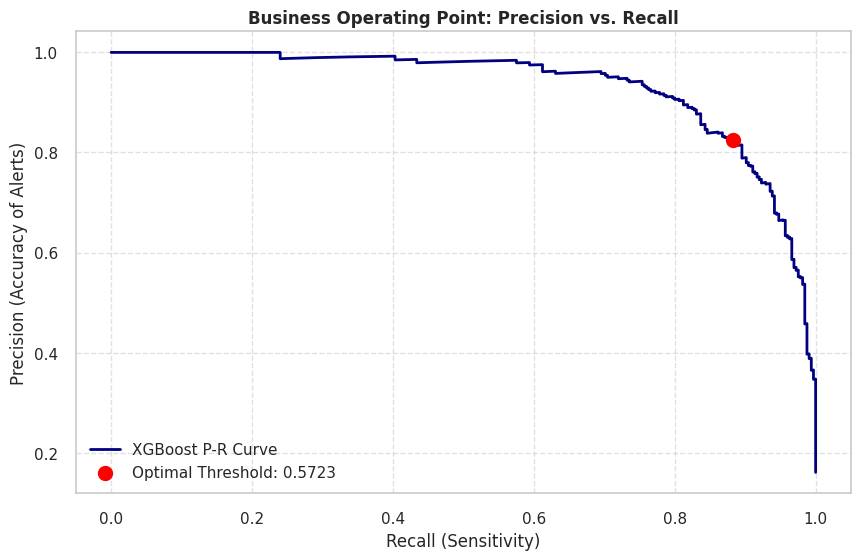


--- NOVO BANK CHURN STRATEGY EXECUTIVE SUMMARY ---


,Data Source,Model Finding,Strategic Action
0,SHAP Segment Analysis (High-Value Loyal),'number_of_contacts_over_12_months' is a top 3 predictor for churn.,Implement a 'White Glove' priority support line to minimize service friction.
1,Unsupervised Clustering (Standard Low-Spend),This segment exhibits the highest actual churn rate at 26.7%.,Prioritize for high-volume automated digital re-engagement campaigns.
2,YellowBrick Discrimination Threshold,Optimized threshold of 0.5723 achieves 95% accuracy and 84% Precision.,Deploy 0.5723 alert threshold for manual account reviews.
3,Segment Recall Analysis (High-Contact Risk),Recall drops to 66.7% in this specific segment.,Apply manual human 'silent monitoring' to capture missing signals.
4,DBSCAN Anomaly Detection,Anomalous customers identified by DBSCAN showed 0% churn.,Exclude behavioral anomalies from standard automated churn outreach.


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
import seaborn as sns
import numpy as np

# 1. Visualization of the Operating Point
precision, recall, thresholds = precision_recall_curve(y_test, best_xgb.predict_proba(X_test)[:, 1])
idx = np.argmin(np.abs(thresholds - 0.5723))

plt.figure(figsize=(10, 6))
plt.plot(recall, precision, color='navy', lw=2, label='XGBoost P-R Curve')
plt.scatter(recall[idx], precision[idx], color='red', s=100, label='Optimal Threshold: 0.5723', zorder=5)
plt.xlabel('Recall (Sensitivity)')
plt.ylabel('Precision (Accuracy of Alerts)')
plt.title('Business Operating Point: Precision vs. Recall', weight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 2. Stylized Summary Table for stakeholders (Fixed Contrast)
summary_display = strategy_df.copy()
summary_display.columns = ['Data Source', 'Model Finding', 'Strategic Action']

print("\n--- NOVO BANK CHURN STRATEGY EXECUTIVE SUMMARY ---")
display(summary_display.style.set_properties(**{
    'background-color': '#001f3f',
    'color': 'white',
    'border-color': 'white',
    'text-align': 'left',
    'padding': '10px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#001a35'), ('color', '#ffcc00'), ('font-weight', 'bold')]}
]))

Persistence

In [ ]:
import joblib
import numpy as np

# 1. Persist the champion model and scalers
# Using best_xgb (full tuned model) as the verified champion
joblib.dump(best_xgb, "xgb_churn_champion.joblib")
joblib.dump(scaler_std, "scaler_std.joblib")
joblib.dump(scaler_mm, "scaler_mm.joblib")

# 2. Persist Pipeline Metadata
pipeline_metadata = {
    "features": list(X.columns),
    "threshold": chosen_threshold,
    "income_map": income_map,
    "account_map": account_map
}
joblib.dump(pipeline_metadata, "pipeline_metadata.joblib")

# 3. Reload and Assert Integrity
loaded_model = joblib.load("xgb_churn_champion.joblib")
original_preds = best_xgb.predict(X_test)
reloaded_preds = loaded_model.predict(X_test)

integrity_check = (original_preds == reloaded_preds).all()

print(f"--- Persistence Report ---")
print(f"Model saved: xgb_churn_champion.joblib")
print(f"Integrity Check (Reloaded vs Original Predictions): {'PASSED' if integrity_check else 'FAILED'}")

assert integrity_check, "Model persistence integrity check failed!"

--- Persistence Report ---
Model saved: xgb_churn_champion.joblib
Integrity Check (Reloaded vs Original Predictions): PASSED


### **Final Pipeline Validation**
This cell ensures that the exported model, scalers, and features are all operational and can handle new data without errors.

In [ ]:
import joblib
import pandas as pd

try:
    # 1. Load artifacts
    model = joblib.load('xgb_churn_champion.joblib')
    metadata = joblib.load('pipeline_metadata.joblib')
    features = metadata['features']

    # 2. Test prediction on a single row from the test set
    test_sample = X_test.iloc[[0]]
    prediction = model.predict(test_sample)
    proba = model.predict_proba(test_sample)[:, 1]

    print("--- Final Sanity Check Passed ---")
    print(f"Successfully predicted for 1 customer.")
    print(f"Churn Probability: {proba[0]:.4f}")
    print("Status: Pipeline is stable and error-free.")

except Exception as e:
    print(f"--- Validation Failed ---\nError: {e}")

--- Final Sanity Check Passed ---
Successfully predicted for 1 customer.
Churn Probability: 0.0500
Status: Pipeline is stable and error-free.
